## Load data
First we will load the data. The data is a dictionary with two keys:
- "header" contains physical parameters we will need for the glider dynamics
- "data" is a Pandas DataFrame

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import random
import scipy
import draw_glider

# Load the data
with open('glider_data.pkl', 'rb') as file:
    loaded_data = pickle.load(file)

# Inspect the header and the dataframe and print some info
print(loaded_data.keys())
header = loaded_data["header"]
df = loaded_data["data"]
n_trials = df["trial"].nunique()
print(header)
print(df.head())
print(f"There are {n_trials} trials")
print(f"Max AoA is {df['aoa'].max()} and min AoA is {df['aoa'].min()}")
print(f"Max elevator deflection is {df['elev'].max()} and min elevator deflection is {df['elev'].min()}")

# Let's normalize AoA and elevator by z score
df["aoa_normalized"] = (df["aoa"] - df["aoa"].mean()) / df["aoa"].std()
df["elev_normalized"] = (df["elev"] - df["elev"].mean()) / df["elev"].std()
df["CL_normalized"] = (df["CL"] - df["CL"].mean()) / df["CL"].std()
df["CD_normalized"] = (df["CD"] - df["CD"].mean()) / df["CD"].std()
df["CM_normalized"] = (df["CM"] - df["CM"].mean()) / df["CM"].std()

# Also partition the data into train and test sets
train_df = df[df["trial"] < int(n_trials * 0.7)]
test_df = df[df["trial"] >= int(n_trials * 0.7)]


dict_keys(['data', 'header'])
{'mass': 0.12, 'I': 0.0017, 'wing_surface_area': 0.0841, 'elev_surface_area': 0.0156, 'RHO': 1.225, 'dt': 0.01}
   trial  time         x         z     pitch  elev        vx        vz  \
0      0  0.00  0.051152  0.009964  0.060968  0.00  7.410968  0.389463   
1      0  0.01  0.112478  0.012091  0.055654 -0.11  7.361156  0.255243   
2      0  0.02  0.173845  0.014051  0.054622 -0.22  7.363071  0.235159   
3      0  0.03  0.295061  0.017256  0.050922 -0.11  7.264967  0.187138   
4      0  0.04  0.355649  0.017893  0.046337 -0.22  7.271573  0.076400   

   pitch_dot  elev_rate        CL        CD        CM       aoa  
0  -0.207727 -23.101458 -0.141395 -0.218126 -0.027938  0.008464  
1  -0.619940 -19.959946  0.030385 -0.184344 -0.013105  0.020994  
2  -0.100132  20.922470  0.149644 -0.152414 -0.002204  0.022695  
3  -0.161671 -14.077252  0.211646 -0.130438  0.002369  0.025169  
4  -0.541209  16.442055  0.222651 -0.116376  0.003121  0.035831  
There are 23 tria

It's usually good practice to inspect the data. Let's visualize the trajectory for a trial


<Figure size 640x480 with 0 Axes>

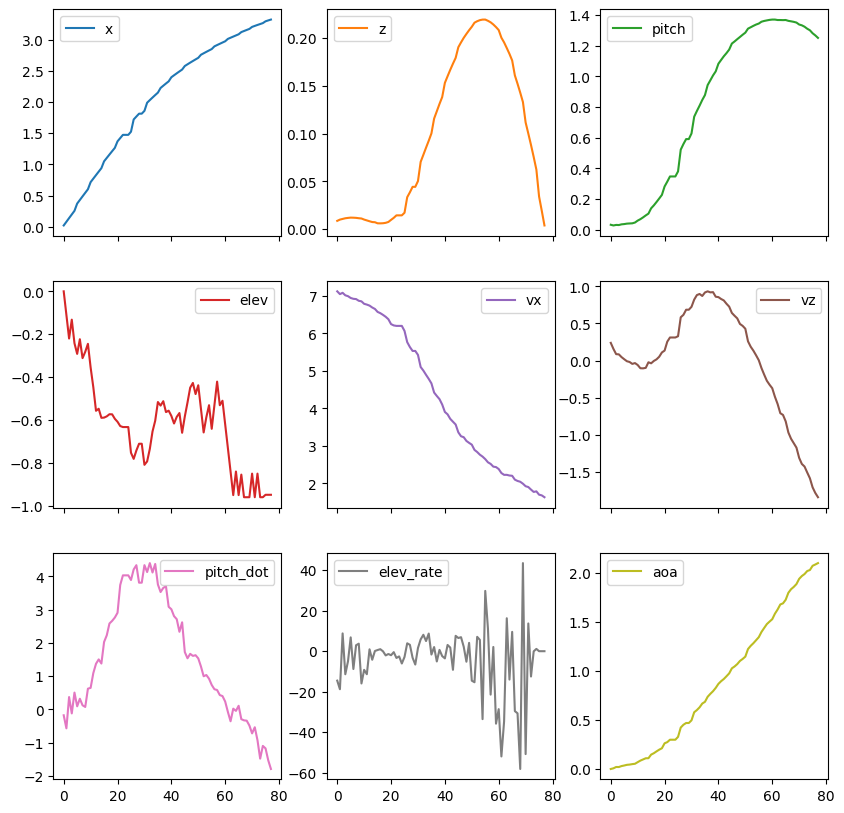

<Figure size 640x480 with 0 Axes>

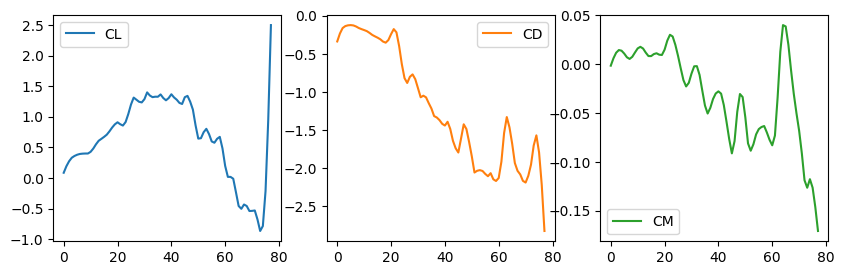

In [3]:
trial = 2
trial_df = df[df["trial"] == trial]

plt.figure()
plt.tight_layout()
states = ["x", "z", "pitch", "elev", "vx", "vz", "pitch_dot", "elev_rate", "aoa"]
trial_df[states].plot(subplots=True, layout=(3, 3), figsize=(10, 10), sharex=True)
plt.figure()
coefs = ["CL", "CD", "CM"] 
trial_df[coefs].plot(subplots=True, layout=(3, 3), figsize=(10, 10), sharex=True)
plt.plot(trial_df["x"], trial_df["z"], label="Trajectory")
plt.grid(True)
plt.xlabel("x (m)")
plt.ylabel("z (m)")
plt.title("Glider Trajectory")
plt.legend()
plt.show()

## Dynamics
We need a dynamics model to simulate the glider given a control input and CL/CD/CM, this is given below.

In [4]:
# Dynamics are x_dot = f(x, u; p) where x is the state, u is the control, and p are the additional parameters CL/CD/CM
def dynamics(state : np.ndarray, control : float, CL : float, CD : float, CM : float):
    x, z, pitch, elev, vx, vz, pitch_dot = state
    elev_rate = control

    # Compute forces and moments from CL, CD, CM
    RHO = 1.225
    m = header["mass"]
    I = header["I"]
    wing_surface_area = header["wing_surface_area"]
    V2 = vx**2 + vz**2
    q = 0.5 * RHO * V2

    # TODO: Add the forces and moment equations
    F_lift = q * CL * wing_surface_area
    F_drag = q * CD * wing_surface_area
    M_pitch = q * CM * wing_surface_area  

    # Compute the freestream velocity angle
    gamma = np.arctan2(vz, vx)
    # Convert lift and drag to world frame forces
    F_x = F_drag * np.cos(gamma) - F_lift * np.sin(gamma)
    F_z = F_drag * np.sin(gamma) + F_lift * np.cos(gamma)

    # Convert to accelerations
    acc_x = F_x / m
    acc_z = F_z / m - 9.81
    acc_pitch = M_pitch / I

    return np.array([vx, vz, pitch_dot, elev_rate, acc_x, acc_z, acc_pitch])

Next, we will rollout the dynamics model from the initial state and ensure the predicted position matches the measured position
Note: there may be a small amount of numerical error here but the trajectories should match pretty closely

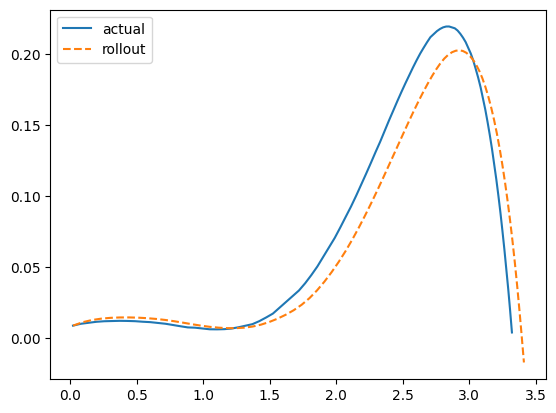

In [5]:
# Let's try rolling out the dynamics using the coefficients and see if we can match the trajectory
x0 = trial_df[["x", "z", "pitch", "elev", "vx", "vz", "pitch_dot"]].to_numpy()[0, :7]
controls = trial_df["elev_rate"].to_numpy()
states = [x0]
dt = header["dt"]
CL = trial_df["CL"].to_numpy()
CD = trial_df["CD"].to_numpy()
CM = trial_df["CM"].to_numpy()
for i, u in enumerate(controls):
    state = states[-1]
    next_state = dynamics(state, u, CL[i], CD[i], CM[i]) * dt + state  # simple Euler step with dt=0.01
    states.append(next_state)
states = np.array(states)
plt.plot(trial_df["x"], trial_df["z"], label=f"trial {i}")
plt.plot(states[:, 0], states[:, 1], label=f"trial {i} rollout", linestyle='--')
plt.legend(["actual", "rollout"])
plt.show()

# RBFs
Let's try to fit RBFs to the train data

In [6]:
def kernel(r : float, gamma : float):
    return np.exp(-gamma * np.linalg.norm(r, axis=-1) ** 2)

# Let's define a grid of centers
aoa_range = np.linspace(-0.0, 4.0, 10)
elev_range = np.linspace(-1.5, 1.5, 10)
CX, CY = np.meshgrid(aoa_range, elev_range)
centers = np.stack([CX.flatten(), CY.flatten()], axis=-1)
gamma = 0.1
lam = 1e-3

x = train_df[["aoa_normalized", "elev_normalized"]].to_numpy()
y_data = train_df[["CL", "CD", "CM"]].to_numpy()

y_data = y_data


# TODO: Compute the kernel matrix Phi, ||x - centers||^2
X = x[:, None, :] - centers[None, :, :]
Phi = kernel(X.reshape(-1,2), gamma).reshape(x.shape[0], centers.shape[0])
# Phi = kernel(x[:, np.newaxis, :] - centers[np.newaxis, :, :], gamma) # (n_samples, n_centers)

# TODO: compute the coefficients theta_cl, theta_cd, theta_cm using ridge regression. You can use np.linalg.inv for the inverse.
# theta = (Phi'Phi + lamI)^-1 Phi'y
theta_cl = np.linalg.inv(Phi.T @ Phi + lam*np.eye(Phi.shape[1])) @ Phi.T @ y_data[:, 0]
theta_cd = np.linalg.inv(Phi.T @ Phi + lam*np.eye(Phi.shape[1])) @ Phi.T @ y_data[:, 1]
theta_cm = np.linalg.inv(Phi.T @ Phi + lam*np.eye(Phi.shape[1])) @ Phi.T @ y_data[:, 2]




## Evaluate the RBF Network on the Test Set
We can evaluate the network by looking at the mean squared error loss on test data (unseen at training time). We can also visualize predictions for a single flight.

MSE for CL: 0.2067
MSE for CD: 0.0955
MSE for CM: 0.0028


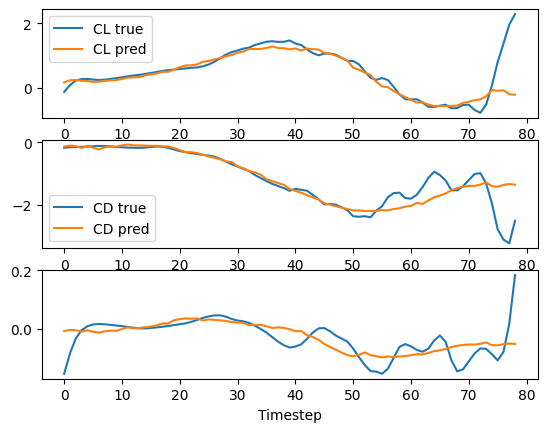

In [7]:
# Let's evaluate the model on the test set
x_test = test_df[["aoa_normalized", "elev_normalized"]].to_numpy()
y_test = test_df[["CL", "CD", "CM"]].to_numpy()
X_test = x_test[:, None, :] - centers[:, :]
Phi_test = kernel(X_test.reshape(-1, 2), gamma).reshape(x_test.shape[0], centers.shape[0])
y_pred_cl = Phi_test @ theta_cl
y_pred_cd = Phi_test @ theta_cd
y_pred_cm = Phi_test @ theta_cm

# Print the mean squared error for each coefficient
mse_cl = np.mean((y_test[:, 0] - y_pred_cl) ** 2)
mse_cd = np.mean((y_test[:, 1] - y_pred_cd) ** 2)
mse_cm = np.mean((y_test[:, 2] - y_pred_cm) ** 2)
print(f"MSE for CL: {mse_cl:.4f}")
print(f"MSE for CD: {mse_cd:.4f}")
print(f"MSE for CM: {mse_cm:.4f}")

# Visualizae a random trial
random_test_trial = 22#random.choice(test_df["trial"].unique())
num_timesteps = len(test_df[test_df["trial"] == random_test_trial])
plt.subplot(3, 1, 1)
plt.plot(y_test[:num_timesteps, 0], label="CL true")
plt.plot(y_pred_cl[:num_timesteps], label="CL pred")
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(y_test[:num_timesteps, 1], label="CD true")
plt.plot(y_pred_cd[:num_timesteps], label="CD pred")
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(y_test[:num_timesteps, 2], label="CM true")
plt.plot(y_pred_cm[:num_timesteps], label="CM pred")    
plt.xlabel("Timestep")

plt.show()

## Simulation Error
Now, we can use the RBF network to simulate a dynamics "rollout". Note that errors will compound over the course of the rollout, and there will be some "simulation error".

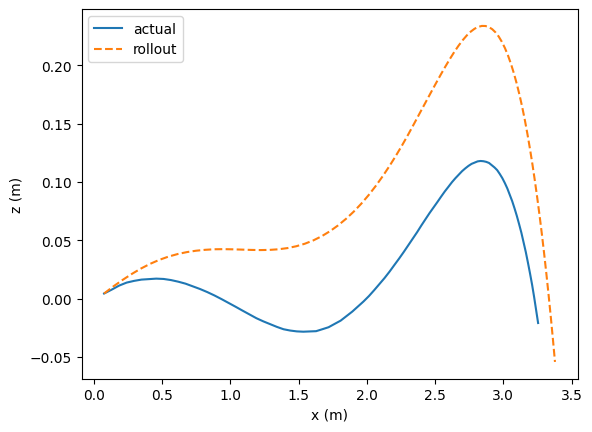

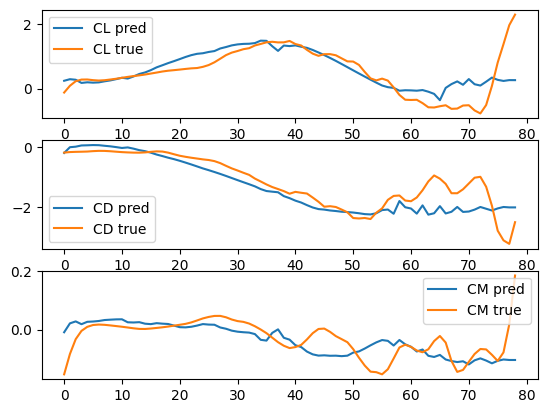

In [8]:

def rollout_with_rbf(x0 : np.ndarray, controls : np.ndarray):
    states = [x0]
    dt = header["dt"]
    predicted_coefs = []
    for i, u in enumerate(controls):
        state = states[-1]
        # TODO compute AoA
        # aoa = pitch - arctan(vz / vx)
        aoa = state[2] - np.arctan2(state[5], state[4])
        elev = state[3]
        # Compute the predicted coefficients using the RBF model
        aoa_normalized = (aoa - df["aoa"].mean()) / df["aoa"].std()
        elev_normalized = (elev - df["elev"].mean()) / df["elev"].std()
        # TODO computed predicted coefficients
        x_new = np.array([[aoa_normalized, elev_normalized]])
        phi_new = kernel(x_new[:, np.newaxis, :] - centers[np.newaxis, :, :], gamma)
        CL_pred = phi_new @ theta_cl
        CD_pred = phi_new @ theta_cd
        CM_pred = phi_new @ theta_cm
        predicted_coefs.append((CL_pred[0], CD_pred[0], CM_pred[0]))
        next_state = dynamics(state, u, CL_pred[0], CD_pred[0], CM_pred[0]) * dt + state  # simple Euler step with dt=0.01
        states.append(next_state)
    states = np.array(states)
    return states, predicted_coefs

# Let's try rolling out the dynamics using the predicted coefficients and see if we can match the trajectory
trial_df = test_df[test_df["trial"] == random_test_trial]
x0 = trial_df[["x", "z", "pitch", "elev", "vx", "vz", "pitch_dot"]].to_numpy()[0, :7]
controls = trial_df["elev_rate"].to_numpy()

states, predicted_coefs = rollout_with_rbf(x0, controls)
aoa = trial_df["aoa"]
plt.plot(trial_df["x"], trial_df["z"], label=f"trial {trial_df['trial'].iloc[0]}")
plt.plot(states[:, 0], states[:, 1], label=f"trial {trial_df['trial'].iloc[0]} rollout", linestyle='--')
plt.legend(["actual", "rollout"])
plt.xlabel("x (m)")
plt.ylabel("z (m)")
plt.figure()
predicted_coefs = np.array(predicted_coefs)
plt.subplot(3, 1, 1)
plt.plot(predicted_coefs[:, 0], label="CL pred")
plt.plot(y_test[:num_timesteps, 0], label="CL true")
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(predicted_coefs[:, 1], label="CD pred")
plt.plot(y_test[:num_timesteps, 1], label="CD true")
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(predicted_coefs[:, 2], label="CM pred")
plt.plot(y_test[:num_timesteps, 2], label="CM true")
plt.legend()
plt.show()

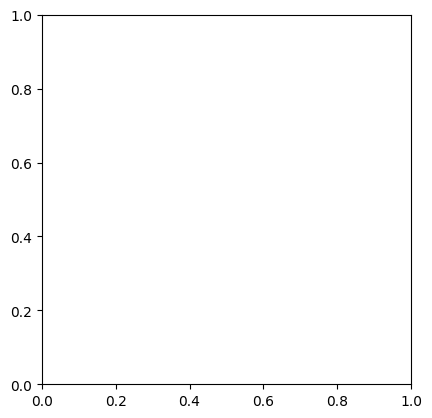

In [9]:
r = draw_glider.Recorder(path="glider_perch.gif")
t = 0.0
for state in states:
    t+=0.01
    draw_glider.draw_glider(t, state, {"xd": [3.5, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], "fixed_axis": True})
    r.save_frame()
    plt.gca().cla()
r.save_movie()
    

# Fully Connected Neural Network
We can attempt the same task with a FCN. Let's define a neural network and a dataset

In [10]:
import torch.nn as nn
import torch.optim as optim
import torch.utils.data
import functools
import torch.nn.functional as F
import time
import tqdm

class CoeffPredictor(nn.Module):

    def __init__(self):
        super().__init__()
        in_dim = 2
        out_dim = 3
        # TODO come up with a neural network architecture. You will want nn.Linear(in, out) and nn.ReLU() layers
        self.mlp = nn.Sequential(
             nn.Linear(in_dim, 64),
             nn.ReLU(),
             nn.Linear(64, 64),
             nn.ReLU(),
             nn.Linear(64, out_dim)
        )

    def forward(self, x : torch.Tensor):
        return self.mlp(x)
    

class GliderDataset(torch.utils.data.Dataset):
    def __init__(self, df, cuda=False):
        self.df = df
        self.cuda = cuda
        self.device = "cuda" if cuda else "cpu"

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        x = torch.tensor(self.df.iloc[idx][["aoa_normalized", "elev_normalized"]].to_numpy(dtype=np.float32)).to(self.device)
        y = torch.tensor(self.df.iloc[idx][["CL_normalized", "CD_normalized", "CM_normalized"]].to_numpy(dtype=np.float32)).to(self.device)
        return x, y


# Train Loop
The loop below trains the neural network. We use mean squared error loss.

In [11]:
def train_fn(epochs=15):
    train_start = time.time()
    dataset = GliderDataset(train_df, cuda=False)
    value_fn = CoeffPredictor()
    #value_fn.to("cuda")
    optimizer = optim.Adam(value_fn.parameters(), lr=0.001)
    trainloader = torch.utils.data.DataLoader(dataset, batch_size=4, shuffle=True)
    #value_fn.to("cuda")
    loss_history = []
    loss = nn.MSELoss()
    for epoch in tqdm.tqdm(range(epochs)):  # loop over the dataset multiple times
        running_loss = 0.0
        for i, data in enumerate(trainloader):
            x, y = data
            optimizer.zero_grad()
            y_hat = value_fn(x)
            loss_value = loss(y_hat.squeeze(), y.squeeze())
            loss_value.backward()
            optimizer.step()

            # print statistics
            running_loss += loss_value.item()
            if i % 1 == 0:
                #print(f'[{epoch + 1}, {i + 1:5d}/{len(dataset)/trainloader.batch_size}] loss: {running_loss / 200:.3f}')
                loss_history.append(running_loss)
                running_loss = 0.0
    torch.save(value_fn.state_dict(), "value_fn.weights")
    train_end = time.time()
    print(f'Finished Training. Took { (train_end - train_start)/60 } minutes')

def load_fn() -> CoeffPredictor:
    learned_val_fn = CoeffPredictor()
    learned_val_fn.load_state_dict(torch.load("value_fn.weights", weights_only=True))
    #learned_val_fn.to("cuda")
    learned_val_fn.eval()
    return learned_val_fn

train_fn()

100%|██████████| 15/15 [00:05<00:00,  2.72it/s]

Finished Training. Took 0.13562150398890177 minutes


## Evaluate NN
We will evaluate the FCN the same way as the RBF. How does the MSE compare to the RBF?

(552, 3) (552, 3)
MSE for CL: 0.2206
MSE for CD: 0.0899
MSE for CM: 0.0029


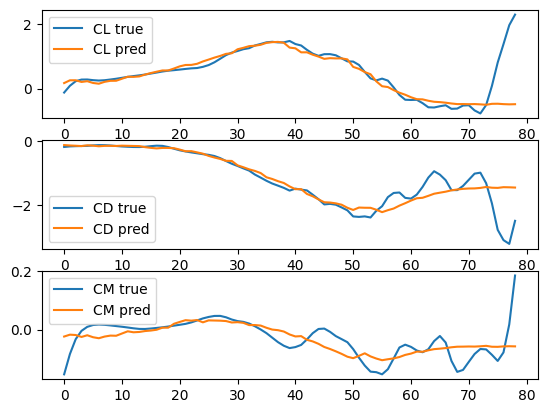

In [12]:
# predict
def test_fn():
    dataset = GliderDataset(test_df, cuda=False)
    value_fn = load_fn()
    testloader = torch.utils.data.DataLoader(dataset, batch_size=1, shuffle=True)
    #value_fn.to("cuda")
    loss_history = []
    loss = nn.MSELoss()
    total_loss = 0
    y_pred = []
    y_actual = []

    for i, data in enumerate(testloader):
        x, y = data
        y_hat = value_fn(x)
        y_pred.append(y_hat.detach().cpu().numpy())
        y_actual.append(y.detach().cpu().numpy())
    y_pred = np.array(y_pred).squeeze()
    y_actual = np.array(y_actual).squeeze()
    # unnormalize
    y_pred[:, 0] = y_pred[:, 0] * df["CL"].std() + df["CL"].mean()
    y_pred[:, 1] = y_pred[:, 1] * df["CD"].std() + df["CD"].mean()
    y_pred[:, 2] = y_pred[:, 2] * df["CM"].std() + df["CM"].mean()
    y_actual[:, 0] = y_actual[:, 0] * df["CL"].std() + df["CL"].mean()
    y_actual[:, 1] = y_actual[:, 1] * df["CD"].std() + df["CD"].mean()
    y_actual[:, 2] = y_actual[:, 2] * df["CM"].std() + df["CM"].mean()

    print(y_pred.shape, y_actual.shape)

    mse_cl = np.mean((y_pred[:, 0] - y_actual[:, 0]) ** 2)
    mse_cd = np.mean((y_pred[:, 1] - y_actual[:, 1]) ** 2)
    mse_cm = np.mean((y_pred[:, 2] - y_actual[:, 2]) ** 2)
    print(f"MSE for CL: {mse_cl:.4f}")
    print(f"MSE for CD: {mse_cd:.4f}")
    print(f"MSE for CM: {mse_cm:.4f}")

test_fn()


predictor = load_fn()
x_test = test_df[["aoa_normalized", "elev_normalized"]].to_numpy()
y_test = test_df[["CL", "CD", "CM"]].to_numpy()
y_pred = predictor(torch.tensor(x_test, dtype=torch.float32)).detach().cpu().numpy()
# need to unnormlaize
y_pred_cl = y_pred[:, 0] 
y_pred_cd = y_pred[:, 1]
y_pred_cm = y_pred[:, 2]
y_pred_cl = y_pred_cl * df["CL"].std() + df["CL"].mean()
y_pred_cd = y_pred_cd * df["CD"].std() + df["CD"].mean()
y_pred_cm = y_pred_cm * df["CM"].std() + df["CM"].mean()

#  a random trial
random_test_trial = 22 #random.choice(test_df["trial"].unique())
num_timesteps = len(test_df[test_df["trial"] == random_test_trial])
plt.subplot(3, 1, 1)
plt.plot(y_test[:num_timesteps, 0], label="CL true")
plt.plot(y_pred_cl[:num_timesteps], label="CL pred")
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(y_test[:num_timesteps, 1], label="CD true")
plt.plot(y_pred_cd[:num_timesteps], label="CD pred")
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(y_test[:num_timesteps, 2], label="CM true")
plt.plot(y_pred_cm[:num_timesteps], label="CM pred")    
plt.legend()
plt.show()

## Simulation Error with Neural Network
Once again we will look at simulation error. How does it compare with the RBF?

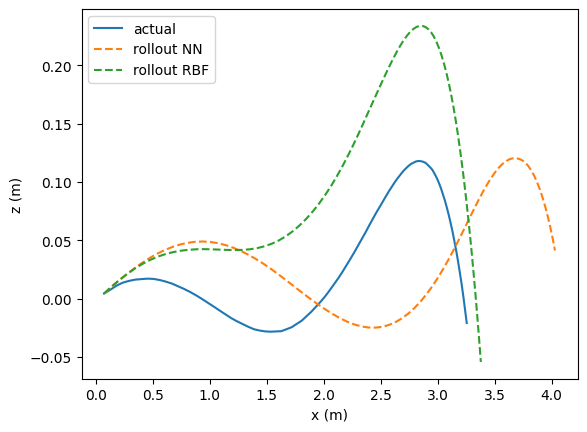

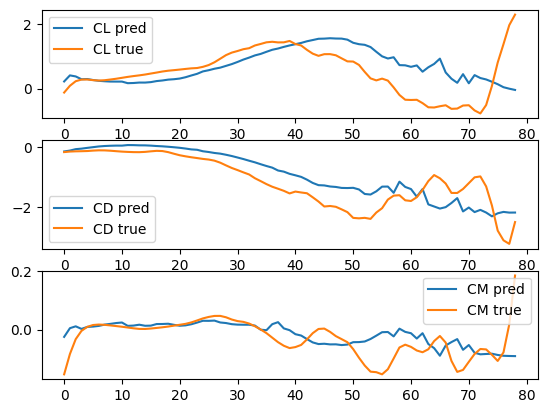

In [13]:
def rollout_with_nn(x0 : np.ndarray, controls : np.ndarray):
    states = [x0]
    dt = header["dt"]
    predicted_coefs = []
    for i, u in enumerate(controls):
        state = states[-1]
        # TODO compute AoA
        aoa = aoa = state[2] - np.arctan2(state[5], state[4])
        elev = state[3]
        aoa_normalized = (aoa - df["aoa"].mean()) / df["aoa"].std()
        elev_normalized = (elev - df["elev"].mean()) / df["elev"].std()
        x_input = np.array([[aoa_normalized, elev_normalized]])
        predictor_input = torch.tensor(x_input, dtype=torch.float32)
        y_pred = predictor(predictor_input).detach().cpu().numpy()
        y_pred_cl = y_pred[:, 0] * df["CL"].std() + df["CL"].mean()
        y_pred_cd = y_pred[:, 1] * df["CD"].std() + df["CD"].mean()
        y_pred_cm = y_pred[:,   2] * df["CM"].std() + df["CM"].mean()
        predicted_coefs.append([y_pred_cl[0], y_pred_cd[0], y_pred_cm[0]])
        next_state = dynamics(state, u, y_pred_cl[0], y_pred_cd[0], y_pred_cm[0]) * dt + state  # simple Euler step with dt=0.01
        states.append(next_state)
    states = np.array(states)
    return states, predicted_coefs

# Let's try rolling out the dynamics using the predicted coefficients and see if we can match the trajectory
trial_df = test_df[test_df["trial"] == random_test_trial]
x0 = trial_df[["x", "z", "pitch", "elev", "vx", "vz", "pitch_dot"]].to_numpy()[0, :7]
controls = trial_df["elev_rate"].to_numpy()

states, predicted_coefs = rollout_with_nn(x0, controls)
states_rbf, _ = rollout_with_rbf(x0, controls)
aoa = trial_df["aoa"]
plt.plot(trial_df["x"], trial_df["z"], label=f"trial {trial_df['trial'].iloc[0]}")
plt.plot(states[:, 0], states[:, 1], label=f"trial {trial_df['trial'].iloc[0]} rollout NN", linestyle='--')
plt.plot(states_rbf[:, 0], states_rbf[:, 1], label=f"trial {trial_df['trial'].iloc[0]} rollout RBF", linestyle='--')
plt.xlabel("x (m)")
plt.ylabel("z (m)")
plt.legend(["actual", "rollout NN", "rollout RBF"])
plt.figure()
predicted_coefs = np.array(predicted_coefs)
plt.subplot(3, 1, 1)
plt.plot(predicted_coefs[:, 0], label="CL pred")
plt.plot(y_test[:num_timesteps, 0], label="CL true")
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(predicted_coefs[:, 1], label="CD pred")
plt.plot(y_test[:num_timesteps, 1], label="CD true")
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(predicted_coefs[:, 2], label="CM pred")
plt.plot(y_test[:num_timesteps, 2], label="CM true")
plt.legend()
plt.show()

## LQR
We can also use our learned model to do control. Lets try regulating to a trim condition (i.e. constant flight path)

Let's try to hold altitude at z = 0

dFdx: [[   0.            0.            0.            0.            1.
     0.            0.        ]
 [   0.            0.            0.            0.            0.
     1.            0.        ]
 [   0.            0.            0.            0.            0.
     0.            1.        ]
 [   0.            0.            0.            0.            0.
     0.            0.        ]
 [   0.            0.          -76.67132533  -24.28654485   -1.75476174
     7.40179055    0.        ]
 [   0.            0.           94.64005875   -4.48515518    2.23448493
   -11.39296847    0.        ]
 [   0.            0.         -204.95054072 -113.76212249   -5.91903687
    22.77220124    0.        ]]
dFdu: [0. 0. 0. 1. 0. 0. 0.]


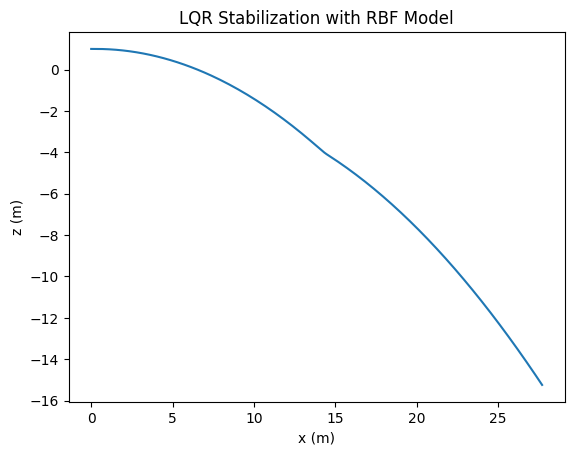

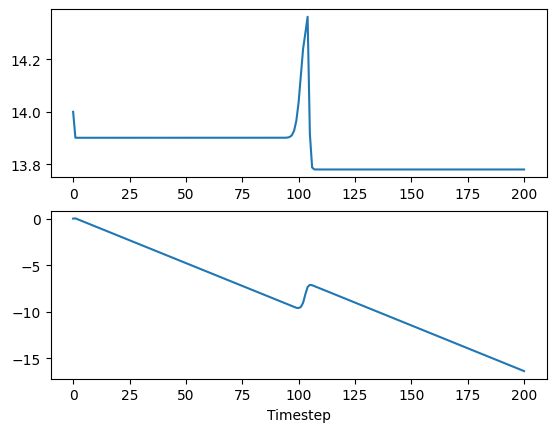

<Figure size 640x480 with 0 Axes>

In [ ]:
# Initial state
x0 = np.array([0.0, 1.0, 0.0, 0.0, 14.0, 0.0, 0.0])
# Target state
xd = np.array([0.0, 0.0, 0.05, 0.0, 9.0, 0.0, 0.0])

def lqr(A, B, Q, R):
    P = scipy.linalg.solve_continuous_are(A, B, Q, R)
    K = np.linalg.solve(R, B.T @ P)
    return K

def dynamics_with_rbf(state : np.ndarray, control : float):
    # TODO compute AoA
    aoa = state[2] - np.arctan2(state[5], state[4])
    elev = state[3]
    # Compute the predicted coefficients using the RBF model
    aoa_normalized = (aoa - df["aoa"].mean()) / df["aoa"].std()
    elev_normalized = (elev - df["elev"].mean()) / df["elev"].std()
    x_input = np.array([[aoa_normalized, elev_normalized]])
    X_input = x_input[:, None, :] - centers[:, :]
    phi_new = kernel(X_input.reshape(-1, 2), gamma).reshape(x_input.shape[0], centers.shape[0])
    CL_pred = phi_new @ theta_cl
    CD_pred = phi_new @ theta_cd
    CM_pred = phi_new @ theta_cm 
    return dynamics(state, control, CL_pred[0], CD_pred[0], CM_pred[0])

def get_dFdx(x0, u0, epsilon=1e-5):
    # Predict the coefficients using the RBF model
    n = len(x0)
    F0 = dynamics_with_rbf(x0, u0)
    dFdx = np.zeros((n, n))
    for i in range(n):
        x_perturbed = x0.copy()
        x_perturbed[i] += epsilon
        F_perturbed = dynamics_with_rbf(x_perturbed, u0)
        dFdx[:, i] = (F_perturbed - F0) / epsilon

    dFdu = np.zeros(n)    
    u_perturbed = u0 + epsilon
    F_perturbed = dynamics_with_rbf(x0, u_perturbed)
    dFdu = (F_perturbed - F0) / epsilon
    return dFdx, dFdu

dFdx, dFdu = get_dFdx(xd, 0.0)
print("dFdx:", dFdx)
print("dFdu:", dFdu)
# TODO: choose a 'Q' matrix for LQR that will let us track the desired flight path. In this case, the first state cooresponds to the 'z' position. We
# ignore the 'x' state of the glider, so the Q matrix will only be 6x6 even though the glider is a 7 dimensional system [x, z, pitch, elev, vx, vz, pitch_dot]
Q = np.diag([1000.0, 1.0, 1.0, 1.0, 1.0, 1.0])
R = np.eye(1)  * 0.1
K = lqr(dFdx[1:, 1:], dFdu[1:].reshape(-1, 1), Q, R)
# Simulate the closed loop system
state = x0
dt = 0.01
states = [state]
for i in range(200):
    state_6dim = state[1:]
    xd_6dim = xd[1:]
    # TODO Compute the control using the LQR policy
    u = -K @ (state_6dim - xd_6dim)
    u = np.squeeze(u)
    state_dot = dynamics_with_rbf(state, u)
    state = state + state_dot * dt
    states.append(state)
states = np.array(states)
plt.plot(states[:, 0], states[:, 1])
plt.xlabel("x (m)")
plt.ylabel("z (m)")
plt.title("LQR Stabilization with RBF Model")
plt.figure()
plt.subplot(2, 1, 1)
plt.plot(states[:, 4], label="vx") 
plt.subplot(2, 1, 2)
plt.plot(states[:, 5], label="vz")
plt.xlabel("Timestep")
plt.figure()
plt.show()  




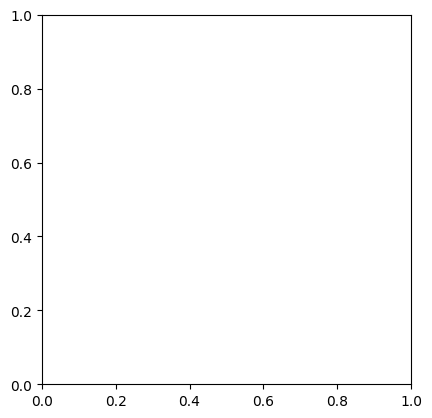

In [17]:

r = draw_glider.Recorder(path="glider_lqr.gif")
t = 0.0
for state in states:
    t+=0.01
    draw_glider.draw_glider(t, state, {"xd": xd, "yline":0.0})
    r.save_frame()
    plt.gca().cla()
r.save_movie()
    